## Load Data

In [1]:
import pandas as pd
df = pd.read_csv('ResaleflatpricesbasedonregistrationdatefromJan2017onwards.csv')

In [2]:
df.head()

,month,town,flat_type,block,street_name,storey_range,floor_area_sqm,flat_model,lease_commence_date,remaining_lease,resale_price
0,2017-01,ANG MO KIO,2 ROOM,406,ANG MO KIO AVE 10,10 TO 12,44.0,Improved,1979,61 years 04 months,232000.0
1,2017-01,ANG MO KIO,3 ROOM,108,ANG MO KIO AVE 4,01 TO 03,67.0,New Generation,1978,60 years 07 months,250000.0
2,2017-01,ANG MO KIO,3 ROOM,602,ANG MO KIO AVE 5,01 TO 03,67.0,New Generation,1980,62 years 05 months,262000.0
3,2017-01,ANG MO KIO,3 ROOM,465,ANG MO KIO AVE 10,04 TO 06,68.0,New Generation,1980,62 years 01 month,265000.0
4,2017-01,ANG MO KIO,3 ROOM,601,ANG MO KIO AVE 5,01 TO 03,67.0,New Generation,1980,62 years 05 months,265000.0


In [3]:
def pre_processing (df):
    # Calculate 'remaining_lease_years' based on 'lease_commence_date'
    # df['remaining_lease_years'] = 99 - (2025 - df['lease_commence_date'])

    remaining_year =  df['remaining_lease'].apply(lambda x: int(x.split(' ')[0]) if 'year' in x else 0)
    remaining_month =  df['remaining_lease'].apply(lambda x: int(x.split(' ')[2]) if 'month' in x else 0)
    remaining_lease = remaining_year + remaining_month / 12
    df['remaining_lease_numeric'] = remaining_lease
    # Drop 'remaining_lease' column
    df = df.drop('remaining_lease', axis=1)

    # Drop 'remaining_lease' column
    df = df.drop('lease_commence_date', axis=1)

    # Create new feature 'price per sqm' in 2 decimal places
    df['price_per_sqm'] = (df['resale_price'] / df['floor_area_sqm']).round(2)

    # drop 'resale_price' and 'floor_area_sqm' columns
    # df = df.drop(['resale_price', 'floor_area_sqm'], axis=1)

    # Drop 'street_name' and 'block' column due to high cardinality
    df = df.drop(['street_name', 'block'], axis=1)

    # Create 'year' and 'month' feature from 'month' column
    df['year'] = pd.to_datetime(df['month']).dt.year
    df['month'] = pd.to_datetime(df['month']).dt.month

    return df

In [4]:
df_clean = pre_processing(df)

In [5]:
df_clean.head()

,month,town,flat_type,storey_range,floor_area_sqm,flat_model,resale_price,remaining_lease_numeric,price_per_sqm,year
0,1,ANG MO KIO,2 ROOM,10 TO 12,44.0,Improved,232000.0,61.333333,5272.73,2017
1,1,ANG MO KIO,3 ROOM,01 TO 03,67.0,New Generation,250000.0,60.583333,3731.34,2017
2,1,ANG MO KIO,3 ROOM,01 TO 03,67.0,New Generation,262000.0,62.416667,3910.45,2017
3,1,ANG MO KIO,3 ROOM,04 TO 06,68.0,New Generation,265000.0,62.083333,3897.06,2017
4,1,ANG MO KIO,3 ROOM,01 TO 03,67.0,New Generation,265000.0,62.416667,3955.22,2017


In [6]:
df_clean.to_csv('train.csv', index=False)

## Train Model

In [7]:
df_clean['flat_type_code'] = df_clean['flat_type'].replace(['1 ROOM', '2 ROOM', '3 ROOM', '4 ROOM', '5 ROOM', 'EXECUTIVE', 'MULTI-GENERATION'], list(range(1, 8)))

/tmp/ipykernel_103223/1547893470.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_clean['flat_type_code'] = df_clean['flat_type'].replace(['1 ROOM', '2 ROOM', '3 ROOM', '4 ROOM', '5 ROOM', 'EXECUTIVE', 'MULTI-GENERATION'], list(range(1, 8)))


In [8]:
# 'storey range' is in '01 to 03' format, create new column to encode based in ascending order
start_floor_unique = df_clean['storey_range'].unique()
# sort based on the starting floor number
start_floor_unique_sorted = sorted(start_floor_unique, key=lambda x: int(x.split(' ')[0]))
df_clean['storey_range_code'] = df_clean['storey_range'].replace(start_floor_unique_sorted, list(range(1, len(start_floor_unique_sorted)+1)))

/tmp/ipykernel_103223/3377156659.py:5: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_clean['storey_range_code'] = df_clean['storey_range'].replace(start_floor_unique_sorted, list(range(1, len(start_floor_unique_sorted)+1)))


In [6]:
import xgboost as xgb
from sklearn.model_selection import train_test_split

# choose columns for features and target
X = df_clean[['flat_type_code', 'storey_range_code', 'remaining_lease_numeric', 'floor_area_sqm', 'flat_model', 'town','year']]
y = df_clean['resale_price']
X['flat_model'] = X['flat_model'].astype('category')
# X['flat_type'] = X['flat_type'].astype('category')
X['town'] = X['town'].astype('category')

# normalize 'floor_area_sqm' and 'remaining_lease_numeric' using min-max scaling
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
X[['floor_area_sqm', 'remaining_lease_numeric']] = scaler.fit_transform(X[['floor_area_sqm', 'remaining_lease_numeric']])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = xgb.XGBRegressor(
    enable_categorical=True,
    tree_method='hist',  # or 'gpu_hist' if using GPU
    random_state=42
)

model.fit(X_train, y_train)

/tmp/ipykernel_100707/2366095332.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X['flat_model'] = X['flat_model'].astype('category')
/tmp/ipykernel_100707/2366095332.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X['town'] = X['town'].astype('category')
/tmp/ipykernel_100707/2366095332.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata

,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,True
,eval_metric,None


In [9]:
model.save_model('xgb_model.json')

In [7]:
# evaluate the model
from sklearn.metrics import mean_absolute_error, mean_squared_error
y_pred = model.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
# calulate r2 score
from sklearn.metrics import r2_score
r2 = r2_score(y_test, y_pred)
print(f"MAE: {mae}, MSE: {mse}, R2: {r2}")

MAE: 27991.398885745566, MSE: 1490421389.2331965, R2: 0.95582572447656


/home/amoskwok/anaconda3/envs/pyspark/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


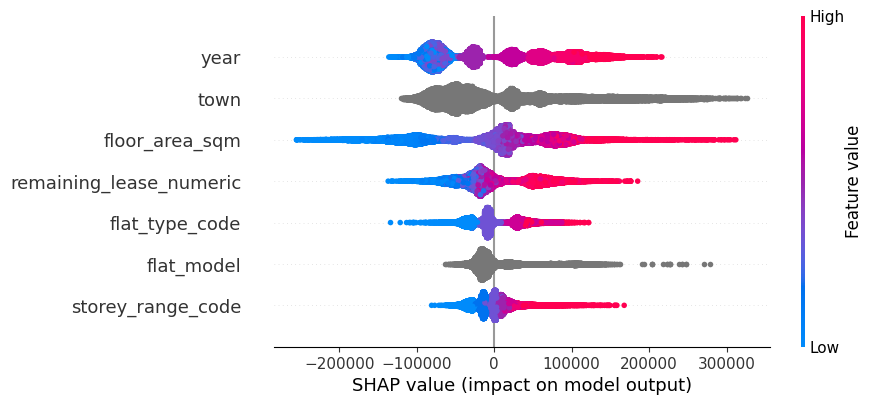

In [8]:
# return shapley values for accessing feature importance
import shap
explainer = shap.Explainer(model)
explanation = explainer(X_test)
shap.plots.beeswarm(explanation)